In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
import pickle

In [15]:
##Load the dataset
data=pd.read_csv("Churn_Modelling.csv")
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [16]:
##Preprocess the data
### Drop irrelavant features
data = data.drop(['RowNumber','CustomerId','Surname'],axis=1)
data

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [17]:
##Encode categorical variable Gender and geography
label_encoder_gender = LabelEncoder()
data['Gender'] = label_encoder_gender.fit_transform(data['Gender'])
data

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,0,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0
2,502,France,0,42,8,159660.80,3,1,0,113931.57,1
3,699,France,0,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,1,39,5,0.00,2,1,0,96270.64,0
9996,516,France,1,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,0,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,1,42,3,75075.31,2,1,0,92888.52,1


In [18]:
## OneHot encode 'Geography'
from sklearn.preprocessing import OneHotEncoder
onehot_encoder_geo = OneHotEncoder()
geo_encoder = onehot_encoder_geo.fit_transform(data[['Geography']])
geo_encoder

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10000 stored elements and shape (10000, 3)>

In [19]:
onehot_encoder_geo.get_feature_names_out(['Geography'])

array(['Geography_France', 'Geography_Germany', 'Geography_Spain'],
      dtype=object)

In [20]:
geo_encoder.toarray()

array([[1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       ...,
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.]], shape=(10000, 3))

In [21]:
geo_encoded_df = pd.DataFrame(geo_encoder.toarray(), columns=onehot_encoder_geo.get_feature_names_out(['Geography']))
geo_encoded_df

,Geography_France,Geography_Germany,Geography_Spain
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0
...,...,...,...
9995,1.0,0.0,0.0
9996,1.0,0.0,0.0
9997,1.0,0.0,0.0
9998,0.0,1.0,0.0


In [22]:
## Combine one hot encoder columns with the original data
data = pd.concat([data.drop('Geography', axis=1),geo_encoded_df],axis=1)
data.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,1.0,0.0,0.0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0.0,0.0,1.0
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1.0,0.0,0.0
3,699,0,39,1,0.00,2,0,0,93826.63,0,1.0,0.0,0.0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0.0,0.0,1.0


In [23]:
## Save the encoders and scaler
with open('label_encoder_gender.pkl','wb') as file:
    pickle.dump(label_encoder_gender,file)

with open('onehot_encoder_geo.pkl','wb') as file:
    pickle.dump(onehot_encoder_geo,file)

In [24]:
## divide the data set into independant and dependant features
X = data.drop('Exited', axis=1)
y = data['Exited']

In [25]:
## Split the data in training and testing sets
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=42)

## Scale these features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
X_train

array([[ 0.35649971,  0.91324755, -0.6557859 , ...,  1.00150113,
        -0.57946723, -0.57638802],
       [-0.20389777,  0.91324755,  0.29493847, ..., -0.99850112,
         1.72572313, -0.57638802],
       [-0.96147213,  0.91324755, -1.41636539, ..., -0.99850112,
        -0.57946723,  1.73494238],
       ...,
       [ 0.86500853, -1.09499335, -0.08535128, ...,  1.00150113,
        -0.57946723, -0.57638802],
       [ 0.15932282,  0.91324755,  0.3900109 , ...,  1.00150113,
        -0.57946723, -0.57638802],
       [ 0.47065475,  0.91324755,  1.15059039, ..., -0.99850112,
         1.72572313, -0.57638802]], shape=(8000, 12))

In [27]:
## saving the scaler file in the pkl format
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler,file)


ANN Implementation-Training an artificial neural network

- Im tensorflow we call ANN a - sequential model
- we will do forward propergation and backward propergation and all these nodes will be interconnected.

- 2x3 = 6 weights

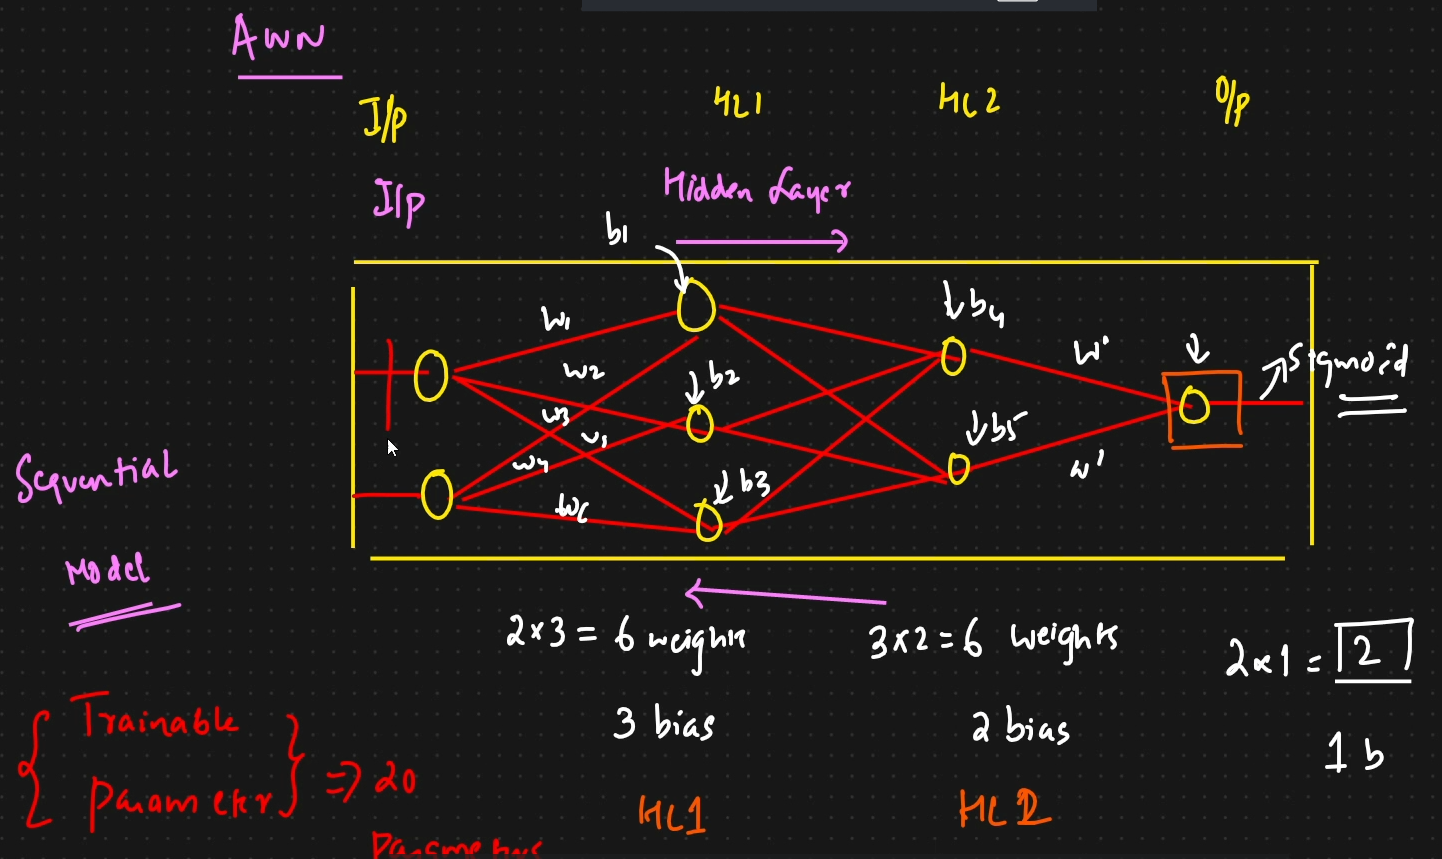

- with the help of 220 trainable parameters we  will be doing the forward propergation and backward propergation.

- sequential network- means it will be interconnected.

- if we just want to create the hidden neurons - keras has a class called Dense

## The key parameters that we will be specifically using

- Sequential n/w- when we start creating our ANN we have to initialize a sequential network n/w

- Dense - if we want to create a hidden neuron we will be using Dense - Hidden neuron, not hidden layer
- Dense i want 64 nodes - in that hidden layer we will be having 64 hidden nodes.
-to even create neurons in the input layer we will be using Dense

- Activation function - in every node we will be applying an activation function

- Optimizer -> in Back propergation -> in updating the weights.

- Loss Function - based the loss function we will be having our gradient descent and we will we reducing this.

- Metrics - Accuracy - classification 

- Training infor - logs - stored logs in some folder - Tensorboard - aim of tensorboard is to display these logs in a way that we will understand it. - some visualization graphs will be used to display it

//alias


In [28]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard
import datetime

inside the model i will be using dense layers.
X_train.shape -> Collumns - get the no of inputs
initially i will take the inputs and create my dense layer. 
and when im creating the dense i will give the input shape- how many no of elements are coming form this input data.
- we are initializing out input with the dense layer


In [29]:

model = Sequential([
    # have to give our input and hidden layer 1 first
    # input_shape - only in te 1st HL u hv to write - because its getting connected to the input layer
    Dense(64,activation='relu',input_shape=(X_train.shape[1],)), #1HL
    Dense(32,activation='relu'), ##HL2
    Dense(1,activation='sigmoid') ##Output layer
])

d:\ANN-Implementations\Customer churn prediction project\venv\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [30]:
model.summary() #Youll see the total no of params - combination of all the weights and bias

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

This is the entire model - and im going to do the forward and backward propergation with respect to this.

in order to do the forward and backward propergation we need to compile this model



In [31]:
import tensorflow
opt=tensorflow.keras.optimizers.Adam(learning_rate=0.01)
loss=tensorflow.keras.losses.BinaryCrossentropy()

## dirently you can use it - you can initialize and use it

In [32]:
## compile the model
#model.compile(optimizer="adam",loss="binary_crossentrophy",metric=['accuracy'])
model.compile(optimizer=opt,loss=loss,metrics=['accuracy'])
## adam has a fixed learning rate
## you need to provide your own learnign rate- so what you can do is import tensorflow and define the learning rate


In [33]:
##we have not yet started the training
## Set up the Tensorboard - to visualize the logs when we start training
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard
## can do manually with matplotlib also

log_dir="logs/fit"+datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorflow_callback = TensorBoard(log_dir=log_dir,histogram_freq=1)

# now lets create tensorlfow_caallback - whats the main aim of this
# use this tensorboard - to import this we need 2 libraries - 

In [34]:
## Set up Early Stopping - when we are training a NN we can train it for multiple/any no of epocs
## even if we state that we r running it for 100 epochs - but model has trained by 20 epochs - after that its only varying by 1 or 2%.-then u dont need to train it for 100 epochs
## when we train - we hv to contiunously monitor our loss val - if its decreasing then its fine - we can train it continuously
## but if the loss val is not decresing-then stop the training-apply earlyStopping
## early stopping callback - like a callback that we use
## ull have multiple keys-val_loss,training_loss, be patience for atleast 5 epochs before  making that decision
## restore the best weights- when your going through the forward and the backward propergation- at which epoch do u find out he best weight - u cn consider that n reload it when u stop the early stopping

early_stopping_calllback=EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)


In [35]:
## Train the model
history=model.fit(
    X_train,y_train,validation_data=(X_test,y_test),epochs=100,
    callbacks=[tensorflow_callback,early_stopping_calllback]
)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8350 - loss: 0.3949 - val_accuracy: 0.8555 - val_loss: 0.3608
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8540 - loss: 0.3586 - val_accuracy: 0.8540 - val_loss: 0.3515
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8571 - loss: 0.3468 - val_accuracy: 0.8575 - val_loss: 0.3488
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8635 - loss: 0.3443 - val_accuracy: 0.8655 - val_loss: 0.3441
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8616 - loss: 0.3406 - val_accuracy: 0.8635 - val_loss: 0.3352
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8601 - loss: 0.3377 - val_accuracy: 0.8630 - val_loss: 0.3419
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8636 - loss: 0.3338 - val_accuracy: 0.8635 - val_loss: 0.3394
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8610 - loss: 0.3348 - val_accu

In [36]:
model.save('model.h5')

In [2]:
## Load Tensorboard Extension
%load_ext tensorboard

In [7]:
%reload_ext tensorboard

In [9]:
%tensorboard --logdir logs/fit20261023-104327

Reusing TensorBoard on port 6007 (pid 30328), started 8:27:46 ago. (Use '!kill 30328' to kill it.)

In [ ]:
### Load the pickle file
